# Dataset generation

Choose the input bounds and airfoils below. Latin hypercube sampling creates
`n_samples` cases, which run in CPU processes. The notebook saves results in DOE order.

| Input | Meaning / units |
| --- | --- |
| `aspect_ratio` | Full-wing aspect ratio |
| `area_m2` | Full-wing planform area, m^2 |
| `taper_ratio` | Tip chord / root chord |
| `tip_twist_deg` | Tip twist relative to the root, degrees |
| `alpha_deg` | Angle of attack, degrees |
| `velocity` | Freestream velocity, m/s |
| `airfoil` | Symmetric airfoil geometry selected from `airfoils` |

The outputs are `CL` and complete modeled wing `CD = profile + induced drag`.


In [1]:
import sys
from pathlib import Path

project_path = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
sys.path.insert(0, str(project_path / "src"))

import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import qmc
from joblib import Parallel, delayed, effective_n_jobs, parallel_config

from solver.geometry import WingParameters, build_wing_geometry
from solver.vlm import solve_vlm_neuralfoil

data_path = project_path / "data"
data_path.mkdir(exist_ok=True)


In [2]:
# Numeric input bounds: (minimum, maximum).
doe_bounds = {
    "aspect_ratio": (4.0, 16.0),
    "area_m2": (0.5, 10.0),
    "taper_ratio": (0.2, 0.5),
    "tip_twist_deg": (-3.0, 0.0),
    "alpha_deg": (2.0, 6.0),
    "velocity": (40.0, 100.0),
}
airfoils = ["naca0012", "naca0015"]  # Example: ["naca0012", "naca0015"].

n_samples = 500
seed = 10

solver_options = {
    "spanwise_resolution": 40,
    "chordwise_resolution": 4,
    "lift_tolerance": 1e-6,
}
output_path = data_path / "wing_data_trial.csv"


In [3]:
# Sample numeric inputs and use the final dimension to select an airfoil.
sampler = qmc.LatinHypercube(d=len(doe_bounds) + 1, seed=seed)
samples = sampler.random(n=n_samples)

doe = pd.DataFrame({
    name: lower + samples[:, i] * (upper - lower)
    for i, (name, (lower, upper)) in enumerate(doe_bounds.items())
})
doe["airfoil"] = [airfoils[int(value * len(airfoils))] for value in samples[:, -1]]

print(f"Latin hypercube DOE: {len(doe)} cases.")
doe


Latin hypercube DOE: 500 cases.


,aspect_ratio,area_m2,taper_ratio,tip_twist_deg,alpha_deg,velocity,airfoil
0,15.977056,9.958054,0.250503,-2.790896,2.387898,43.103690,naca0015
1,15.043798,8.889915,0.353626,-0.082952,3.109294,69.090909,naca0012
2,8.012150,1.185265,0.343913,-0.412473,4.398885,52.491217,naca0015
3,5.491522,9.044180,0.212618,-1.473107,2.933420,69.966108,naca0015
4,10.687990,6.852106,0.272507,-2.131499,5.169041,48.567956,naca0015
...,...,...,...,...,...,...,...
495,8.812273,5.103567,0.492995,-0.890350,3.695805,91.307814,naca0012
496,13.573904,1.361520,0.290604,-0.988148,4.584895,90.542316,naca0012
497,12.352249,9.343448,0.249263,-0.902055,5.317859,90.472433,naca0015
498,12.283941,4.745426,0.497189,-2.136624,3.160071,80.033673,naca0015


In [4]:
# -2: all CPUs except one; -1: all CPUs; 1: serial; or choose a worker count.
n_jobs = -2


def solve_case(case_id, case, solver_options):
    from solver.geometry import WingParameters, build_wing_geometry
    from solver.vlm import solve_vlm_neuralfoil

    parameters = WingParameters(
        aspect_ratio=case["aspect_ratio"],
        area_m2=case["area_m2"],
        taper_ratio=case["taper_ratio"],
        tip_twist_deg=case["tip_twist_deg"],
        airfoil=case["airfoil"],
        sweep_deg=0.0,
    )
    geometry = build_wing_geometry(parameters)
    result = solve_vlm_neuralfoil(
        geometry,
        alpha=case["alpha_deg"],
        velocity=case["velocity"],
        **solver_options,
    )

    return {
        "case_id": case_id,
        "geometry_id": geometry.geometry_id(),
        **case.to_dict(),
        "reynolds": result["reynolds"],  # Derived from velocity and mean aerodynamic chord.
        "CL": result["CL"],
        "CD": result["CD"],
        "max_lift_error": result["max_lift_error"],
        "runtime_s": result["total_runtime_s"],
    }


In [5]:
rows = []

# Keep one numerical-library thread per worker to avoid CPU oversubscription.
with parallel_config(backend="loky", inner_max_num_threads=1):
    with Parallel(
        n_jobs=min(effective_n_jobs(n_jobs), len(doe)),
        return_as="generator", batch_size=1,
    ) as parallel:
        results = parallel(
            delayed(solve_case)(case_id, case, solver_options)
            for case_id, case in doe.iterrows()
        )
        for row in results:
            rows.append(row)
            df = pd.DataFrame(rows)
            df.to_csv(output_path, index=False)
            print(f"Completed {len(rows)}/{len(doe)}: CL = {row['CL']:.4f}")

df


KeyboardInterrupt: 

# Data Viz

Run this section on its own to plot the saved CSV without generating data again.


In [6]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

plot_project_path = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
plot_df = pd.read_csv(plot_project_path / "data" / "wing_data_trial.csv")
plot_output_dir = plot_project_path / "results" / "feature_plots"
plot_output_dir.mkdir(parents=True, exist_ok=True)

features = {
    "aspect_ratio": "Aspect ratio",
    "area_m2": "Planform area [m$^2$]",
    "taper_ratio": "Taper ratio",
    "tip_twist_deg": "Tip twist [deg]",
    "alpha_deg": "Angle of attack [deg]",
    "velocity": "Velocity [m/s]",
}
outputs = [("CL", "Lift coefficient CL"), ("CD", "Total wing drag coefficient CD")]
airfoil_groups = list(plot_df.groupby("airfoil", sort=True))
colors = plt.get_cmap("tab10").colors
markers = ["o", "^", "s", "D"]


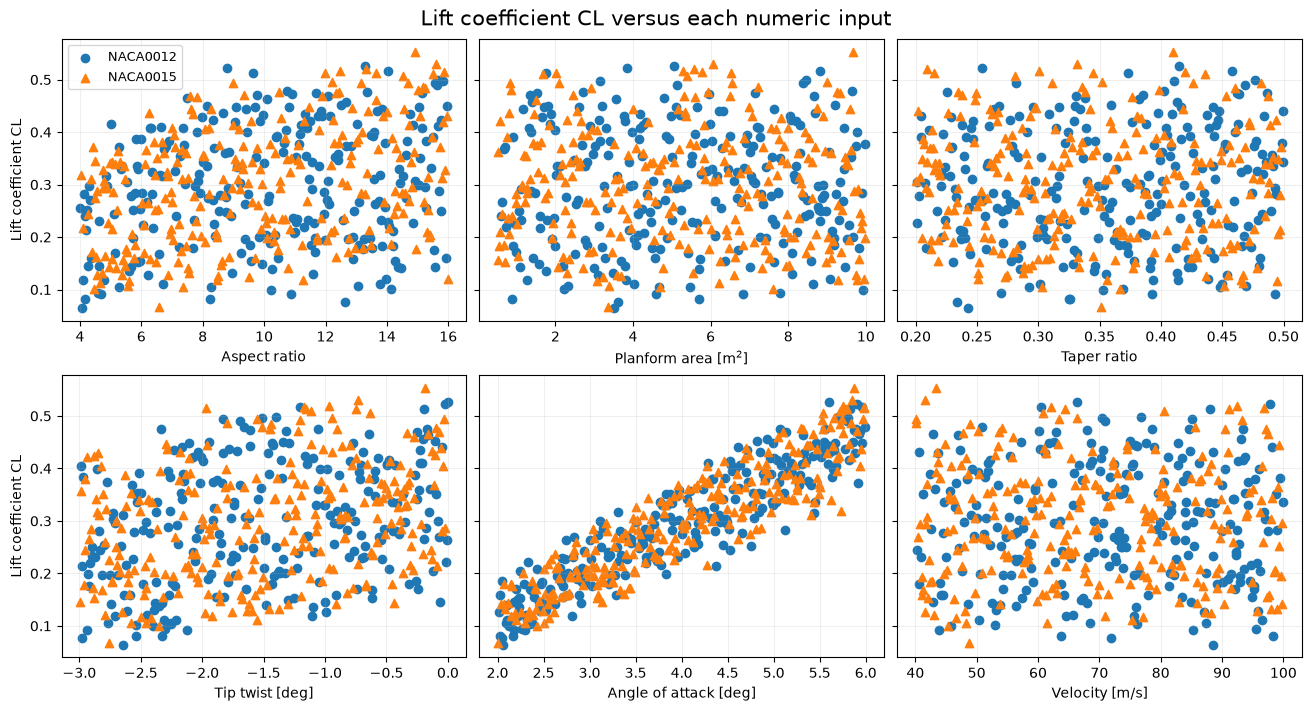

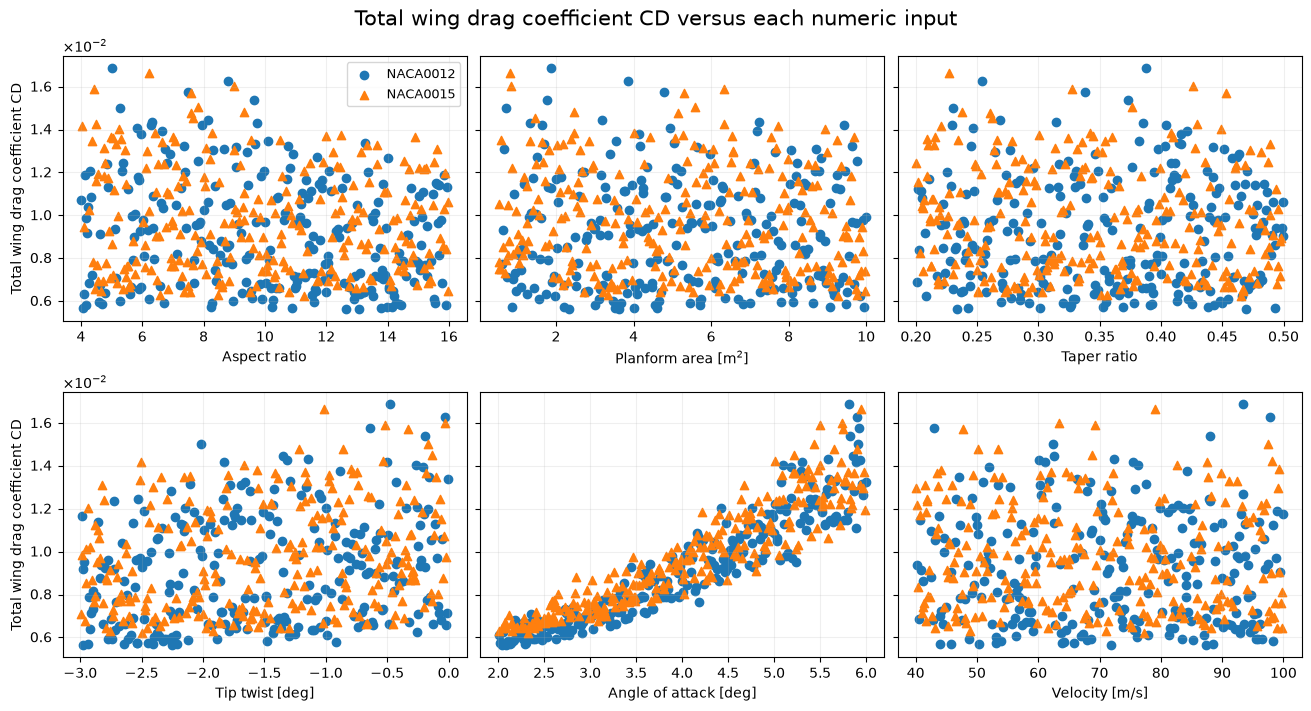

In [7]:
for output, output_label in outputs:
    fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharey=True, layout="constrained")
    fig.suptitle(f"{output_label} versus each numeric input", fontsize=15)

    for ax, (feature, feature_label) in zip(axes.flat, features.items()):
        for i, (name, group) in enumerate(airfoil_groups):
            ax.scatter(
                group[feature], group[output], label=name.upper(),
                color=colors[i % len(colors)], marker=markers[i % len(markers)])
        ax.set_xlabel(feature_label)
        ax.grid(alpha=0.2)
        if output == "CD":
            ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0), useMathText=True)

    for ax in axes[:, 0]:
        ax.set_ylabel(output_label)
    axes[0, 0].legend(fontsize=9)
    fig.savefig(plot_output_dir / f"{output}_vs_numeric_inputs.png", dpi=160, bbox_inches="tight")
    plt.show()


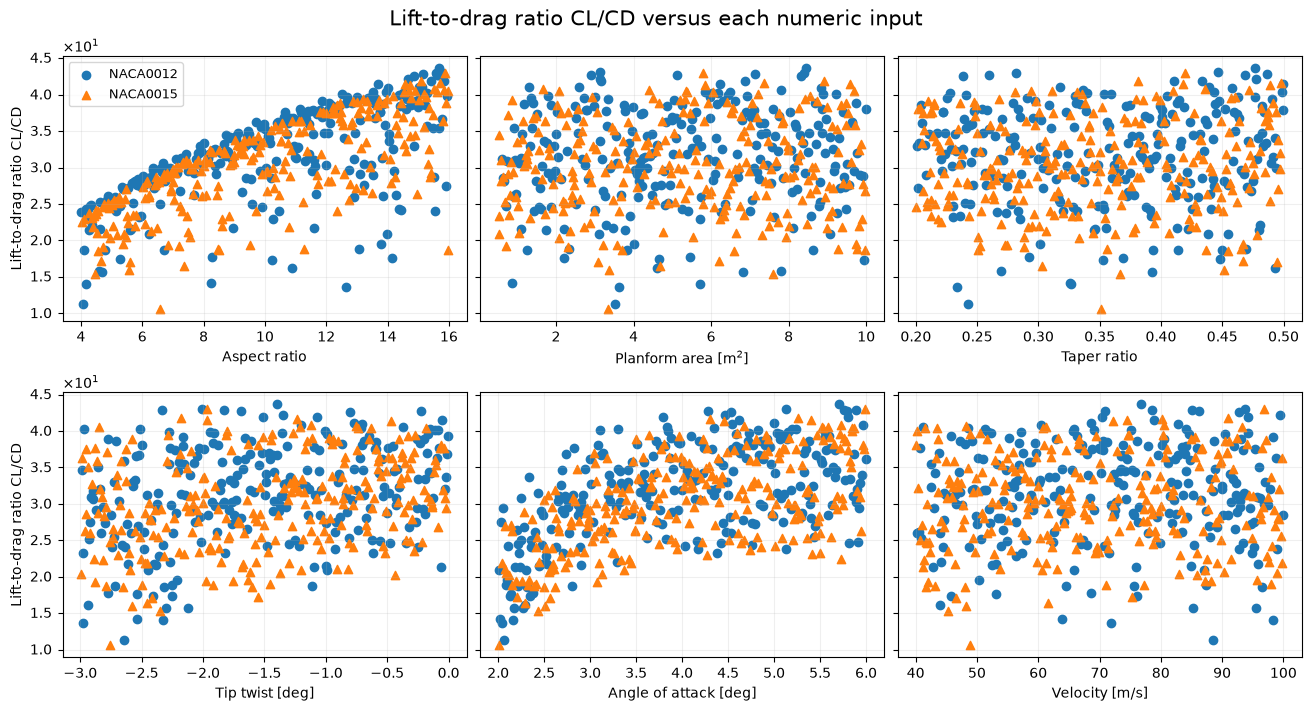

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharey=True, layout="constrained")
fig.suptitle(f"Lift-to-drag ratio CL/CD versus each numeric input", fontsize=15)

for ax, (feature, feature_label) in zip(axes.flat, features.items()):
    for i, (name, group) in enumerate(airfoil_groups):
        ax.scatter(
            group[feature], group["CL"]/group["CD"], label=name.upper(),
            color=colors[i % len(colors)], marker=markers[i % len(markers)])
    ax.set_xlabel(feature_label)
    ax.grid(alpha=0.2)
    if output == "CD":
        ax.ticklabel_format(axis="y", style="sci", scilimits=(0, 0), useMathText=True)

for ax in axes[:, 0]:
    ax.set_ylabel("Lift-to-drag ratio CL/CD")
axes[0, 0].legend(fontsize=9)
fig.savefig(plot_output_dir / f"{output}_vs_numeric_inputs.png", dpi=160, bbox_inches="tight")
plt.show()